# **Spectral Modularity Clustering on the Karate Club Graph**

## 1. Contains the necessary libraries, initial graph and other objects to be used in this code.

In [92]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

G = nx.karate_club_graph()
H = G.copy()
f,e = 0, 1
Metrics_Name = ["Degree centrality", "Betweenness centrality",
           "Closeness centrality", "Clustering coefficent" ]
Colour_Name = ["Red","RoyalBlue","Green","Yellow","Violet"]
Metrics_Values = np.zeros((4,34,8))

## 2. Following are the functions defined for the partitioning based on modularity.

### 2.1 Forming the Modularity Matrix B of the Karate Club Graph.

In [93]:
def Master_B (A,m):
    global Master_B
    k = np.sum(A, axis = 1)
    B = A - ((np.outer(k,k))/(2*m))
    Master_B = B

### 2.2 Forming the Modularity Matrix B for a given subgraph.

In [94]:
def Calc_B (g):
    global Master_B
    C = list(g.nodes)
    Idx = np.ix_(*(C,C))
    return Master_B[Idx]

### 2.3 Calculating the Modularity Score of a graph, and returning hard clustering vector s if the score is positive.

In [95]:
  
def Modularity (B , m):
    
    eigvalues , eigvectors = np.linalg.eigh(B)
    try:
        ev_max = np.max(eigvalues)
    except ValueError:
        ev_max = 0
    
    if ev_max > 0:
        ev_maxid = np.argmax(eigvalues)
        u = eigvectors[:,ev_maxid]
        s = ((u > 0).astype(int) * 2) - 1
        return s
    else:
        return np.zeros(1)

### 2.4 Returns the Community lists after partition, if the Modularity is positive.

In [96]:
def Partition (A,g,m):
    
    B = Calc_B(g)
    s = Modularity(B, m)
    
    if s.any() == bool(np.False_):
        C1, C2 = [], [] 
    else:
        community_dict = {node:int(val) for node, val in zip(g.nodes(), s.flatten())}
        C1, C2 = [], []
        for i in community_dict.keys():
            if community_dict[i] == 1:
                C1.append(i)
            elif community_dict[i] == -1:
                C2.append(i)
    return C1, C2

### 2.5 Forms the Subgraph object, from the Community list.

In [97]:
def Remove_Edges(A,C1,C2):
    H = G.copy()
    I = G.copy()
    J = G.copy()
    K = G.copy()
    
    H.remove_nodes_from(C1)
    I.remove_nodes_from(C2)

    J.remove_edges_from(H.edges(data=True))
    J.remove_edges_from(I.edges(data=True))
    K.remove_edges_from(J.edges)
        
    return K

### 2.6 Calculate the four Centrality mMtrics value for all the nodes.

In [98]:
def Calc_Metrics(g):
    global Metrics_Name
    global f
    global Metrics_Values

    a = nx.degree_centrality(g)
    
    for i in a.keys():
        Metrics_Values[0][i][f:] = a[i]
            
    a = nx.betweenness_centrality(g)
    for i in a.keys():
        Metrics_Values[1][i][f:] = a[i]
            
    a = nx.closeness_centrality(g)
    for i in a.keys():
        Metrics_Values[2][i][f:] = a[i]
            
    a = nx.clustering(g)
    for i in a.keys():
        Metrics_Values[3][i][f:] = a[i]
            
    f += 1

### 2.7 Plots the Graph after each Partitioning.

In [99]:
def Plot(g):
    global e
    global pos
    global H
    global Colour_Name
    global Colours
    global Components
    
    H1 = H.copy()
    H2 = H.copy()
    H3 = H.copy()
    g1 = g.copy()
       
    H1.remove_nodes_from(g1)

    H2.remove_edges_from(g1.edges(data=True))
    H2.remove_edges_from(H1.edges(data=True))
    H3.remove_edges_from(H2.edges)
    
    if nx.utils.graphs_equal(H3,H):
        return
    H = H3
    
    Colours = ["Grey"]*34
    z=0
    Components = list(nx.connected_components(H))
    for i in Components:
        for j in i:
            Colours[j] = Colour_Name[z]
        z += 1    
        
    plt.figure(e, figsize=(10,8))
    plt.title(f"After {e-1}th Partitioning")
    nx.draw_networkx_nodes(H3, pos ,node_color = Colours, node_size=300)
    nx.draw_networkx_edges(H3, pos, alpha=0.5)
    nx.draw_networkx_labels(H3, pos, font_size=10)
    e += 1
    

### 2.8 The main Recursive Code that operates on the Karate Club Graph.
#### Recursive calls on each subgraph , untill all possible communities are formed.

In [100]:
def Recursive_Modularity_Clustering(G,m):
    global e
    global pos
    global Metrics_Values

    A = nx.to_numpy_array(G, weight="none") #into numpy matrix
    C1,C2 = [],[]
    C1, C2 = Partition(A,G,m)
    if C1 == [] or C2 == []:
        return G
    else:
        K = Remove_Edges(G, C1, C2)
        Plot(K)
        
        Subg1 = K.subgraph(C1).copy()
        Subg2 = K.subgraph(C2).copy()
        
        Calc_Metrics(Subg1)
        Calc_Metrics(Subg2)
        
        subg1 = Recursive_Modularity_Clustering(Subg1,m)
        subg2 = Recursive_Modularity_Clustering(Subg2,m)
        K = nx.compose(subg1, subg2)
        
        return K
        

### 2.9 Function that initiates the Recursive Algorithm.

In [101]:
def Graph(G):
    A = nx.to_numpy_array(G, weight="none") #into numpy matrix 
    m = (np.sum(A))/2
    Master_B(A,m)
    return Recursive_Modularity_Clustering(G,m)

## 3. Zachary's Karate Club Graph.

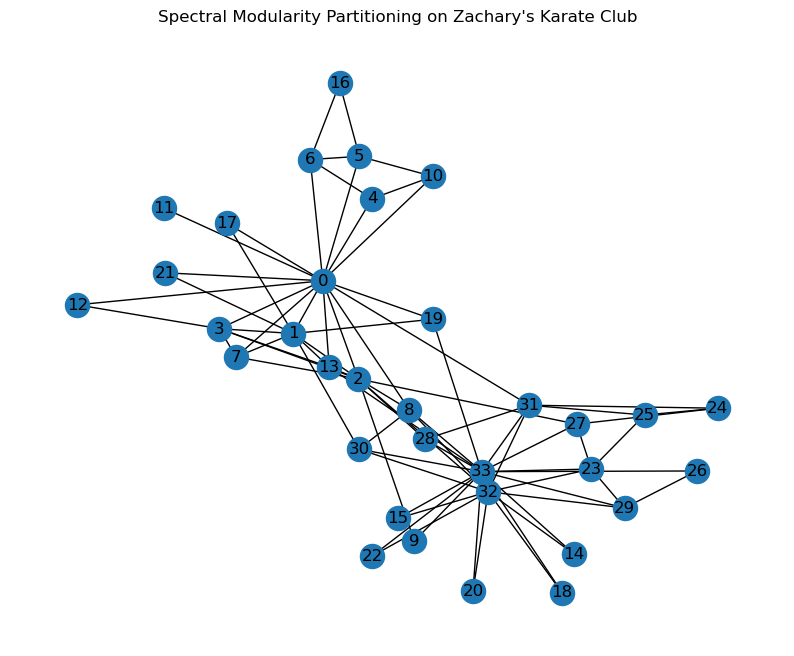

In [102]:
plt.figure(figsize=(10, 8))
plt.title("Spectral Modularity Partitioning on Zachary's Karate Club")

pos = nx.spring_layout(G, seed=42)
plt.figure(e)
nx.draw(G,pos, with_labels=True)
e += 1

## 4. Initiating the Modularity Algorithm, and Plotting graph after each partition.

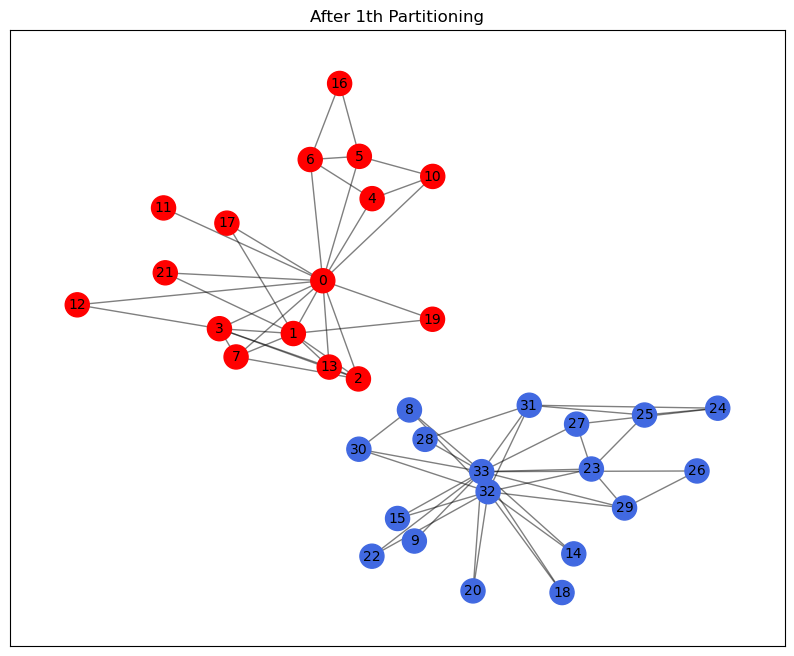

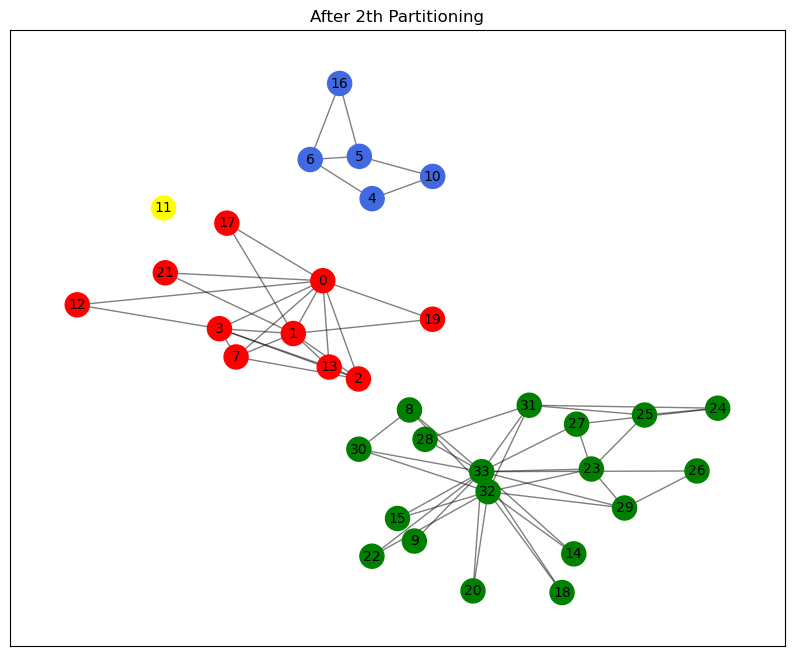

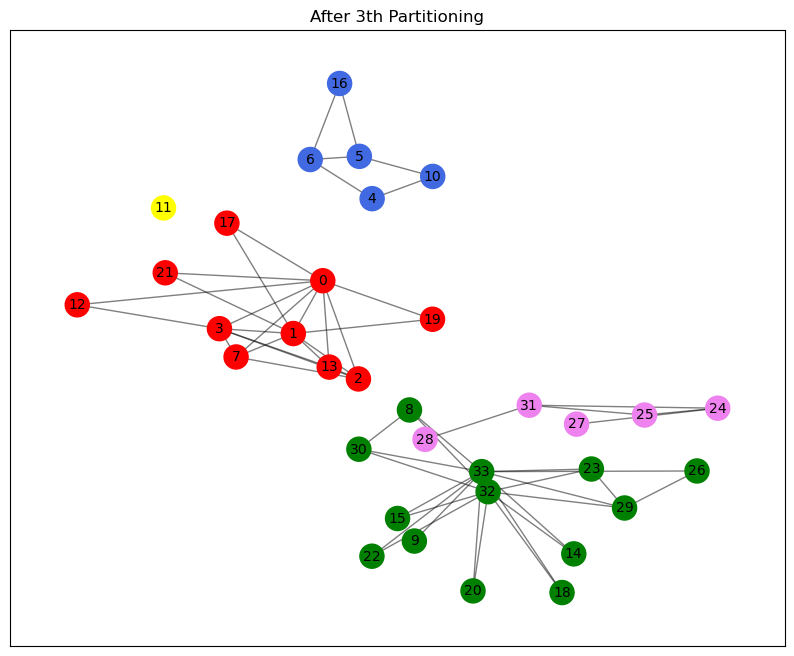

In [103]:
g = Graph(G)

## 5. The Final Commmunity Clusters and Modularity Score, after applying the Algorithm.

Final Spectral Modularity Score of the graph : 0.43014561196379375


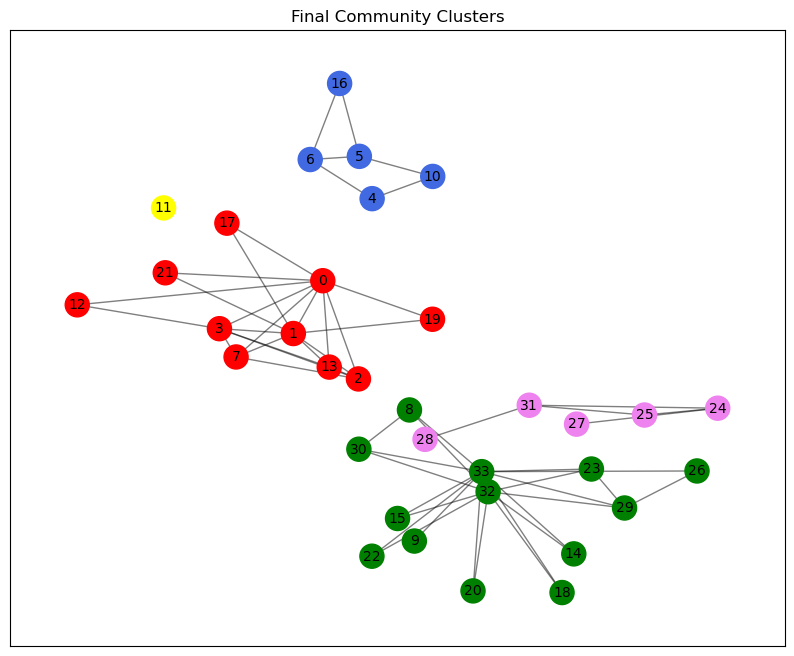

In [104]:
plt.figure(e, figsize=(10,8))
plt.title("Final Community Clusters")
nx.draw_networkx_nodes(G, pos,node_color = Colours, node_size=300)
nx.draw_networkx_edges(g, pos, alpha=0.5)
nx.draw_networkx_labels(g, pos, font_size=10)
plt.plot()
e += 1

print("Final Spectral Modularity Score of the graph :",nx.algorithms.community.modularity(G,Components))

## 6. Evolution of each Metrics Value after each iteration, of all nodes.

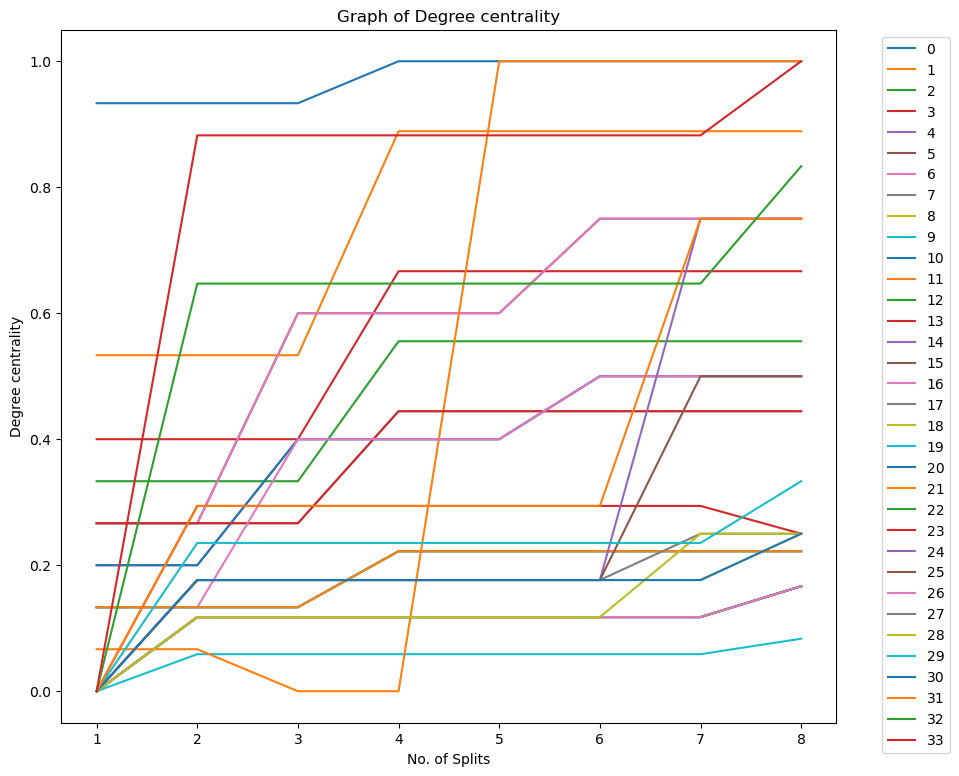

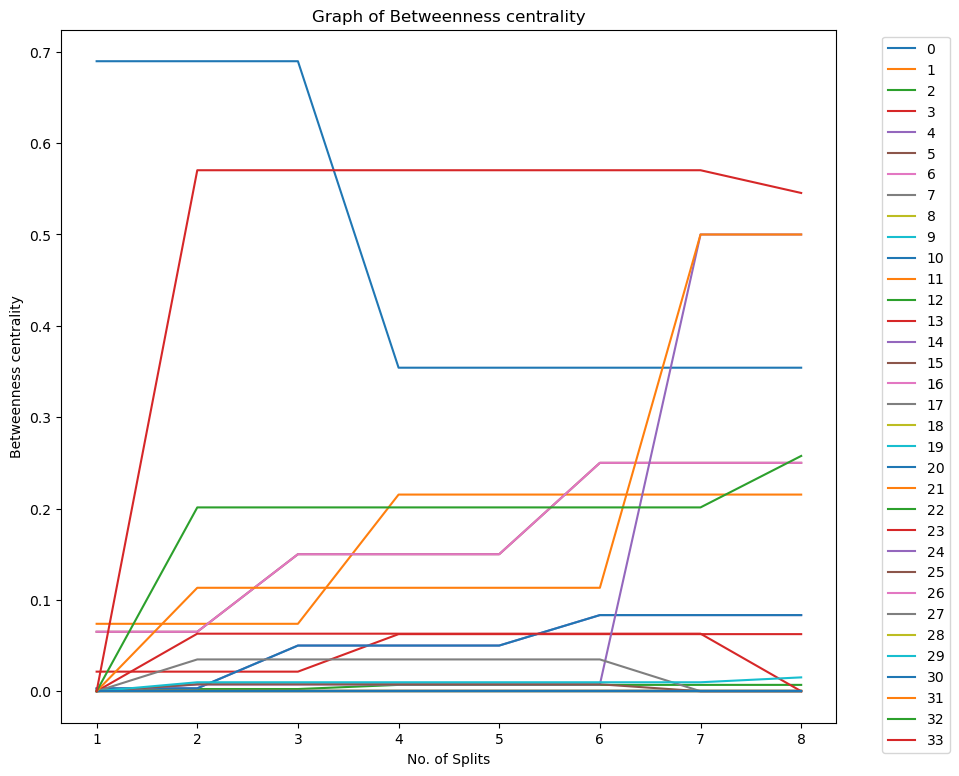

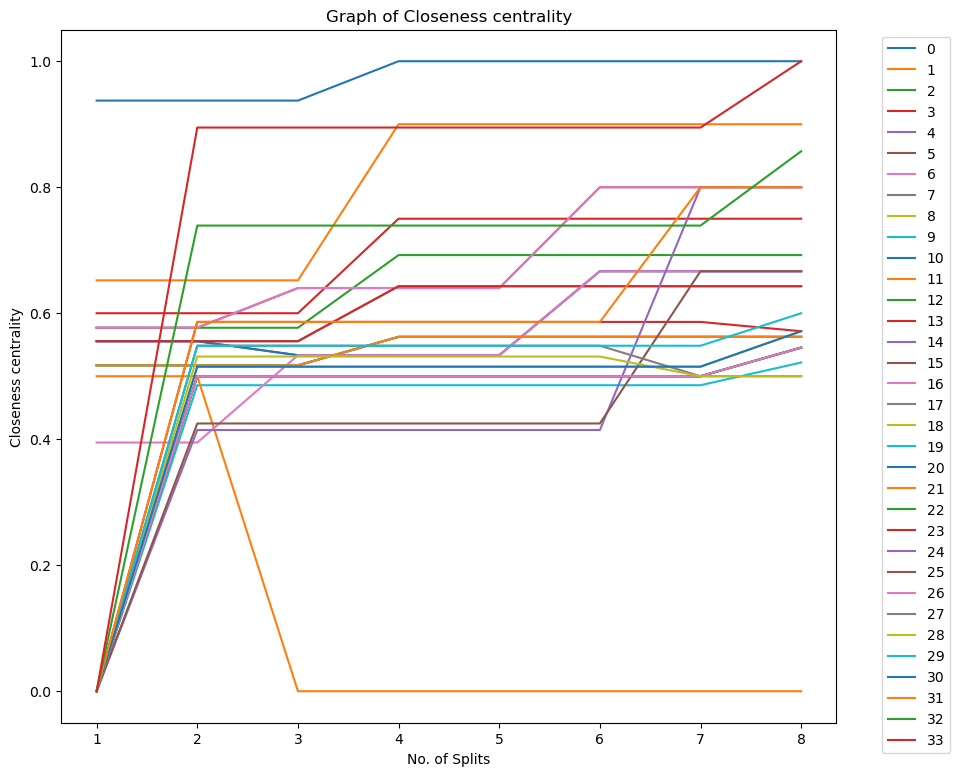

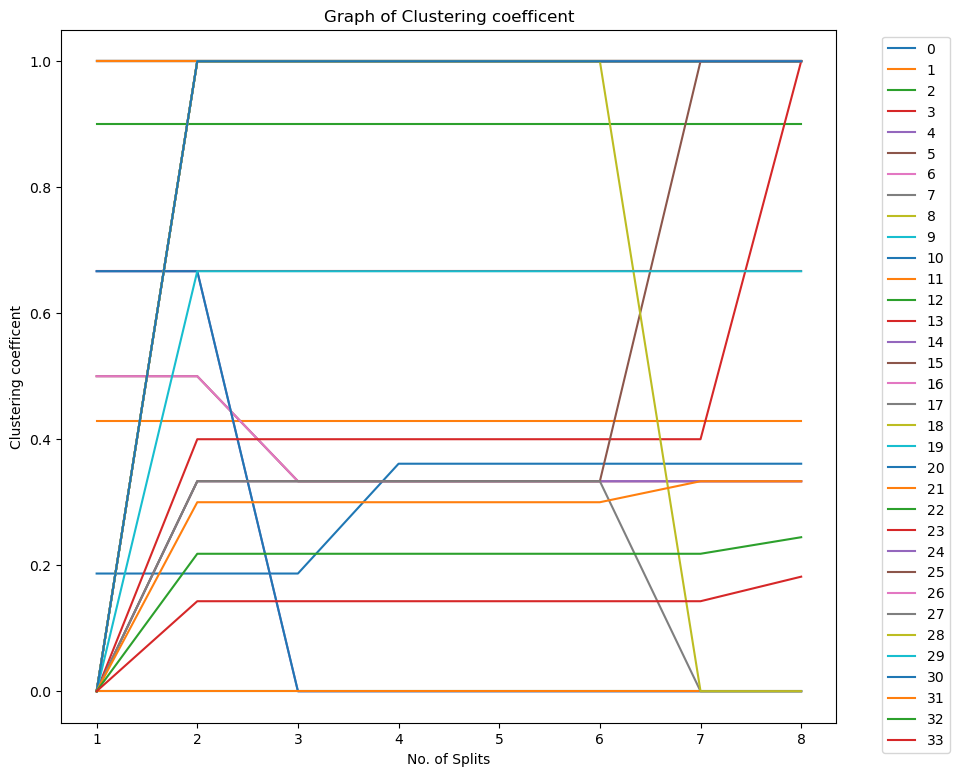

In [105]:
x = [x for x in range(1,9)]

for j in [0,1,2,3]:
    plt.figure(e, figsize=(10, 9))
    e += 1
    for i in range(0,34):
        plt.title(f"Graph of {Metrics_Name[j]}")
        plt.xlabel("No. of Splits")
        plt.ylabel(Metrics_Name[j])
        plt.plot(x, list(Metrics_Values[j][i]), label= str(i))
        plt.legend(bbox_to_anchor=(1.05, 1), loc="best")